In [1]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from scipy.fft import dct, idct

Διαστάσεις: (1500, 2250)
Min: 2.0
Max: 254.0


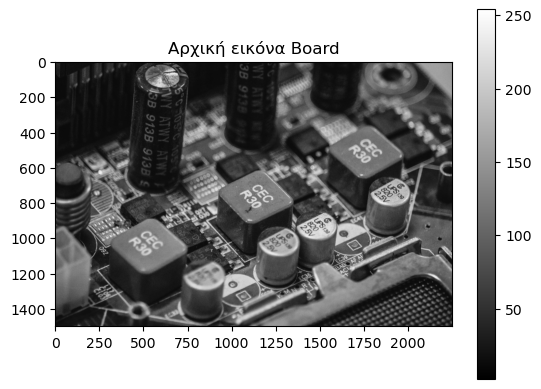

In [2]:
# Φόρτωση εικόνας
img = np.array(Image.open('board.png').convert('L'), dtype=float)

print(f"Διαστάσεις: {img.shape}")
print(f"Min: {img.min()}")
print(f"Max: {img.max()}")

plt.imshow(img, cmap='gray')
plt.title('Αρχική εικόνα Board')
plt.colorbar()
plt.show()

In [3]:
# Κόβουμε την εικόνα ώστε να διαιρείται ακριβώς με 32
H, W = img.shape
H_new = (H // 32) * 32
W_new = (W // 32) * 32
img_crop = img[:H_new, :W_new]

print(f"Νέες διαστάσεις: {img_crop.shape}")
print(f"Αριθμός blocks: {H_new//32} x {W_new//32} = {(H_new//32)*(W_new//32)}")

Νέες διαστάσεις: (1472, 2240)
Αριθμός blocks: 46 x 70 = 3220


DCT υπολογίστηκε για όλα τα blocks!


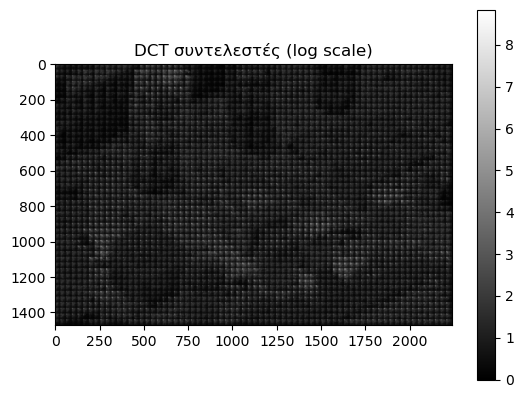

In [4]:
from scipy.fft import dct, idct

def dct2(block):
    """2D-DCT με μέθοδο γραμμών-στηλών"""
    return dct(dct(block, axis=0, norm='ortho'), axis=1, norm='ortho')

def idct2(block):
    """2D-IDCT με μέθοδο γραμμών-στηλών"""
    return idct(idct(block, axis=0, norm='ortho'), axis=1, norm='ortho')

# Εφαρμογή DCT σε όλα τα blocks
H_new, W_new = img_crop.shape
dct_blocks = np.zeros_like(img_crop)

for i in range(0, H_new, 32):
    for j in range(0, W_new, 32):
        block = img_crop[i:i+32, j:j+32]
        dct_blocks[i:i+32, j:j+32] = dct2(block)

print("DCT υπολογίστηκε για όλα τα blocks!")

# Εμφάνιση DCT (log scale)
plt.imshow(np.log(1 + np.abs(dct_blocks)), cmap='gray')
plt.title('DCT συντελεστές (log scale)')
plt.colorbar()
plt.show()

In [5]:
def compress_dct(img_crop, r, method='zonal'):
    H_new, W_new = img_crop.shape
    reconstructed = np.zeros_like(img_crop)
    block_size = 32
    keep = int(r * block_size * block_size)
    
    for i in range(0, H_new, block_size):
        for j in range(0, W_new, block_size):
            block = img_crop[i:i+32, j:j+32]
            D = dct2(block)
            mask = np.zeros_like(D)
            
            if method == 'zonal':
                # Κρατάμε πάνω αριστερά τριγωνική ζώνη
                count = 0
                for u in range(block_size):
                    for v in range(block_size):
                        if u + v < block_size and count < keep:
                            mask[u, v] = 1
                            count += 1
            else:
                # Threshold: κρατάμε τους μεγαλύτερους
                flat = np.abs(D).ravel()
                thresh = np.sort(flat)[::-1][keep-1]
                mask = (np.abs(D) >= thresh).astype(float)
            
            D_compressed = D * mask
            reconstructed[i:i+32, j:j+32] = idct2(D_compressed)
    
    return reconstructed

print("Συναρτήσεις έτοιμες!")

Συναρτήσεις έτοιμες!


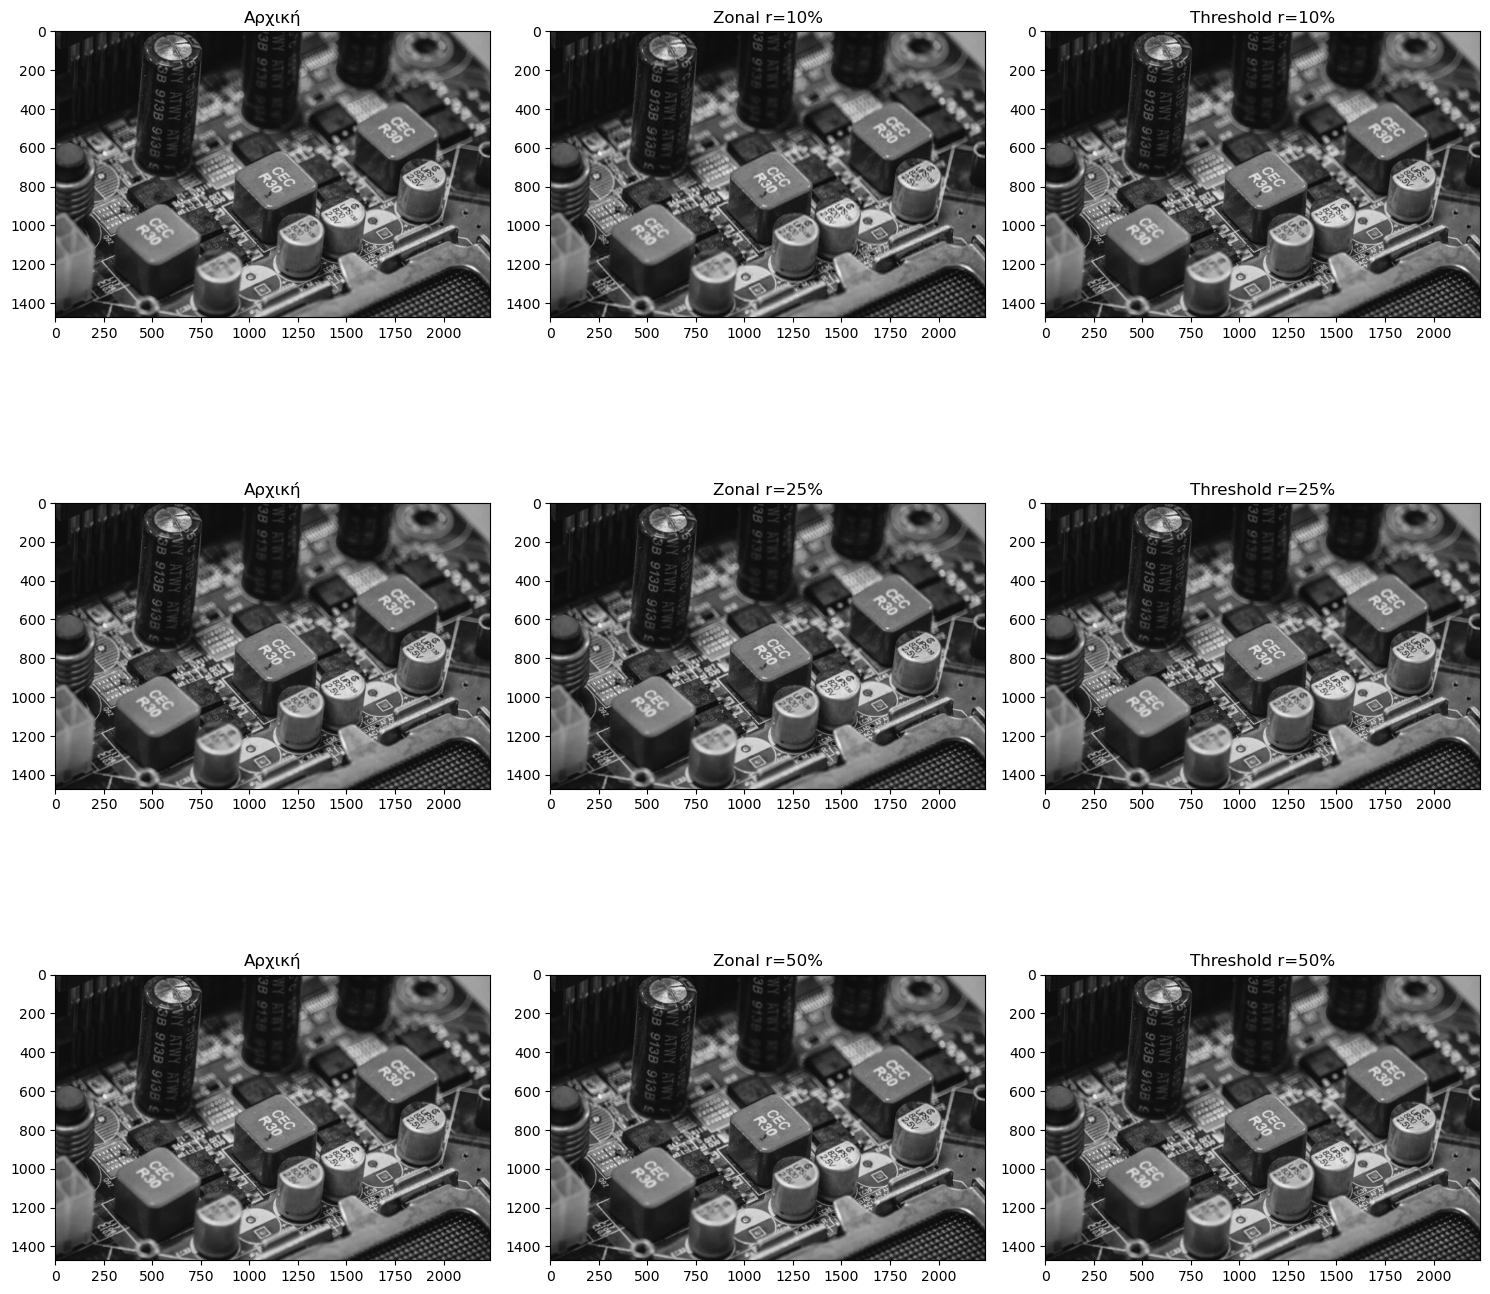

Έτοιμο!


In [6]:
# Δοκιμή για r = 10%, 25%, 50%
ratios = [0.10, 0.25, 0.50]

fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for i, r in enumerate(ratios):
    img_zonal = compress_dct(img_crop, r, method='zonal')
    img_thresh = compress_dct(img_crop, r, method='threshold')
    
    axes[i, 0].imshow(img_crop, cmap='gray', vmin=0, vmax=255)
    axes[i, 0].set_title('Αρχική')
    
    axes[i, 1].imshow(np.clip(img_zonal, 0, 255), cmap='gray', vmin=0, vmax=255)
    axes[i, 1].set_title(f'Zonal r={int(r*100)}%')
    
    axes[i, 2].imshow(np.clip(img_thresh, 0, 255), cmap='gray', vmin=0, vmax=255)
    axes[i, 2].set_title(f'Threshold r={int(r*100)}%')

plt.tight_layout()
plt.show()
print("Έτοιμο!")

r=5% done
r=10% done
r=15% done
r=20% done
r=25% done
r=30% done
r=40% done
r=50% done


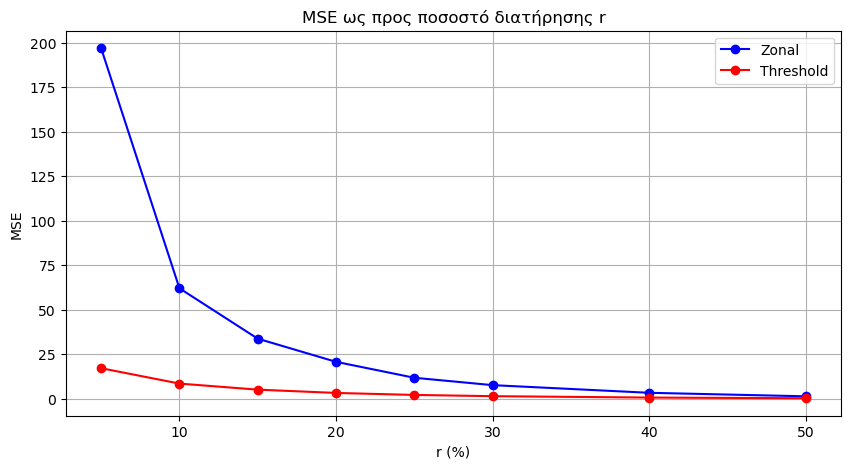

In [7]:
# MSE για r από 5% έως 50%
ratios_all = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
mse_zonal = []
mse_thresh = []

for r in ratios_all:
    img_z = compress_dct(img_crop, r, method='zonal')
    img_t = compress_dct(img_crop, r, method='threshold')
    mse_zonal.append(np.mean((img_crop - img_z)**2))
    mse_thresh.append(np.mean((img_crop - img_t)**2))
    print(f"r={int(r*100)}% done")

# Καμπύλες MSE
plt.figure(figsize=(10, 5))
plt.plot([r*100 for r in ratios_all], mse_zonal, 'b-o', label='Zonal')
plt.plot([r*100 for r in ratios_all], mse_thresh, 'r-o', label='Threshold')
plt.xlabel('r (%)')
plt.ylabel('MSE')
plt.title('MSE ως προς ποσοστό διατήρησης r')
plt.legend()
plt.grid(True)
plt.show()

Threshold (κόκκινο):

Ξεκινά με πολύ χαμηλό MSE ακόμα και στο 5%
Πέφτει γρήγορα και φτάνει σχεδόν στο 0 από το 25%

Zonal (μπλε):

Ξεκινά με πολύ υψηλό MSE (~200) στο 5%
Πέφτει γρήγορα αλλά παραμένει πάντα χειρότερο από το Threshold
Στο 50% τα δύο συγκλίνουν
Συμπέρασμα:
Η μέθοδος Threshold υπερέχει σαφώς της Zonal για όλα τα ποσοστά r. Αυτό είναι λογικό γιατί:

Η Zonal κρατά πάντα τους συντελεστές βάσει θέσης — ακόμα και αν κάποιοι είναι μικροί
Η Threshold κρατά τους σημαντικότερους συντελεστές ανεξαρτήτως θέσης — άρα πάντα διατηρεί τη μέγιστη πληροφορία